# Análisis de uso del gimnasio

Tres preguntas: **cuándo se llena el gym**, **si los planes están bien dimensionados** y **qué clientes hay que contactar**.

Requiere Mongo levantado y los datos cargados (`python scripts/seed.py`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()
db = MongoClient(os.getenv("MONGO_URI", "mongodb://localhost:27017/?directConnection=true"), tz_aware=True)[os.getenv("MONGO_DB", "gym")]
TZ = "America/Argentina/Cordoba"
AHORA = pd.Timestamp.now(tz="UTC")
Path("graficos").mkdir(exist_ok=True)
print({c: db[c].count_documents({}) for c in ["planes", "clientes", "asistencias"]})

Matplotlib is building the font cache; this may take a moment.


{'planes': 6, 'clientes': 95, 'asistencias': 396}


## 1. ¿Cuándo se llena el gym?

El día y la hora se calculan en Mongo con la zona horaria de Córdoba, porque las fechas están guardadas en UTC.

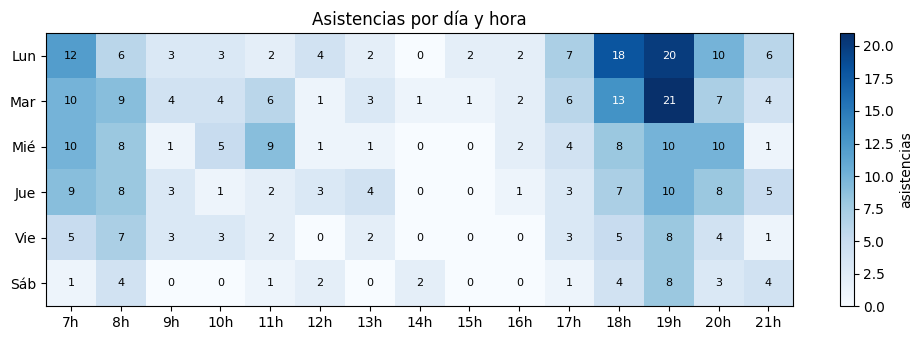

Turno más lleno: Mar 19h (21 asistencias)
18 a 20h concentra el 44% de las asistencias


In [2]:
asistencias = pd.DataFrame(db.asistencias.aggregate([
    {"$project": {"_id": 0,
                  "dia": {"$isoDayOfWeek": {"date": "$fecha_hora", "timezone": TZ}},
                  "hora": {"$hour": {"date": "$fecha_hora", "timezone": TZ}}}}
]))
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]
mapa = pd.crosstab(asistencias["dia"], asistencias["hora"]).reindex(index=range(1, 7), fill_value=0)
mapa.index = dias

fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(mapa, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(mapa.columns)), [f"{h}h" for h in mapa.columns])
ax.set_yticks(range(len(dias)), dias)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > mapa.values.max() * 0.6 else "black")
ax.set_title("Asistencias por día y hora")
fig.colorbar(im, ax=ax, label="asistencias")
plt.tight_layout(); plt.savefig("graficos/mapa_calor.png", dpi=150); plt.show()

pico = mapa.stack().idxmax()
franja_pico = asistencias["hora"].between(18, 20).mean()
print(f"Turno más lleno: {pico[0]} {pico[1]}h ({mapa.loc[pico]} asistencias)")
print(f"18 a 20h concentra el {franja_pico:.0%} de las asistencias")

**Lectura:** hay dos picos, 7–8h y 18–20h. Lunes y martes a la noche son los turnos más cargados. Entre las 14 y las 16h casi no va nadie.

## 2. ¿Los planes están bien dimensionados?

Comparar cupos usados contra cupos totales engaña, porque muchos planes recién empiezan. Por eso se **proyecta** el uso al final del período: usados ÷ fracción del mes transcurrida.

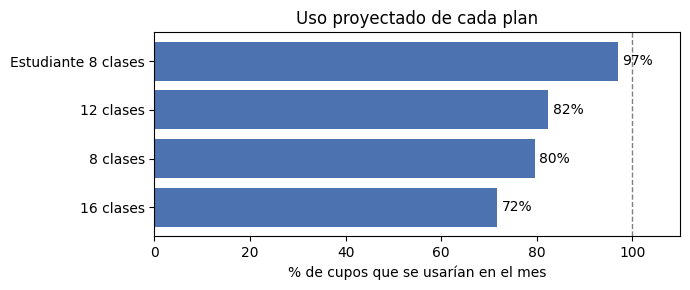

,clientes,uso_proyectado,se_quedan_cortos
plan_actual.nombre,,,
16 clases,11,72%,18%
8 clases,23,80%,35%
12 clases,24,82%,42%
Estudiante 8 clases,5,97%,80%


In [3]:
clientes = pd.json_normalize(list(db.clientes.find({}, {"estado": 1, "plan_actual": 1})))
vigentes = clientes[(clientes["estado"] == "activo") & (clientes["plan_actual.fecha_vencimiento"] > AHORA)].copy()

con_cupos = vigentes[vigentes["plan_actual.cupos_totales"].notna()].copy()
total = con_cupos["plan_actual.cupos_totales"]
usados = total - con_cupos["plan_actual.cupos_restantes"]
transcurrido = ((AHORA - con_cupos["plan_actual.fecha_inicio"]).dt.total_seconds() / (30 * 86400)).clip(0.05, 1)
con_cupos["uso_proyectado"] = (usados / transcurrido).clip(upper=total) / total
con_cupos["se_queda_corto"] = usados / transcurrido >= total

uso = (con_cupos.groupby("plan_actual.nombre")
       .agg(clientes=("uso_proyectado", "size"), uso_proyectado=("uso_proyectado", "mean"),
            se_quedan_cortos=("se_queda_corto", "mean"))
       .sort_values("uso_proyectado"))

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(uso.index, uso["uso_proyectado"] * 100, color="#4C72B0")
ax.axvline(100, color="gray", ls="--", lw=1)
for i, v in enumerate(uso["uso_proyectado"] * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
ax.set_xlim(0, 110); ax.set_xlabel("% de cupos que se usarían en el mes")
ax.set_title("Uso proyectado de cada plan")
plt.tight_layout(); plt.savefig("graficos/uso_planes.png", dpi=150); plt.show()
uso.style.format({"uso_proyectado": "{:.0%}", "se_quedan_cortos": "{:.0%}"})

**Lectura:** el plan de 16 clases es el menos aprovechado. Los planes chicos, en cambio, se usan casi completos, y una parte de esos clientes se va a quedar sin cupos antes de fin de mes.

## 3. Ingresos y clientes a contactar

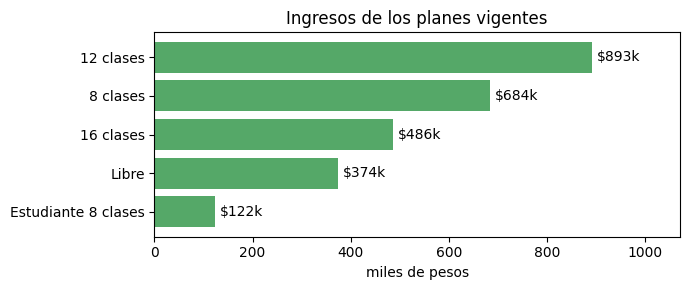

Ingresos vigentes: $2,559,500 — ticket promedio $36,564


,clientes
Plan vencido (no renovaron),10
Sin plan asignado,8
"Sin cupos, con plan vigente",5
Vence en los próximos 7 días,13


In [4]:
ingresos = vigentes.groupby("plan_actual.nombre")["plan_actual.precio_pagado"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(ingresos.index, ingresos / 1000, color="#55A868")
for i, v in enumerate(ingresos / 1000):
    ax.text(v + 10, i, f"${v:,.0f}k", va="center")
ax.set_xlabel("miles de pesos"); ax.set_title("Ingresos de los planes vigentes")
ax.set_xlim(0, ingresos.max() / 1000 * 1.2)
plt.tight_layout(); plt.savefig("graficos/ingresos.png", dpi=150); plt.show()

activos = clientes[clientes["estado"] == "activo"]
a_contactar = pd.Series({
    "Plan vencido (no renovaron)": (activos["plan_actual.fecha_vencimiento"] <= AHORA).sum(),
    "Sin plan asignado": activos["plan_actual.fecha_vencimiento"].isna().sum(),
    "Sin cupos, con plan vigente": (vigentes["plan_actual.cupos_restantes"] == 0).sum(),
    "Vence en los próximos 7 días": (vigentes["plan_actual.fecha_vencimiento"] <= AHORA + pd.Timedelta(days=7)).sum(),
}, name="clientes")
print(f"Ingresos vigentes: ${ingresos.sum():,.0f} — ticket promedio ${vigentes['plan_actual.precio_pagado'].mean():,.0f}")
a_contactar.to_frame()

**Lectura:** el plan de 12 clases es el que más factura. Hay unos 30 clientes activos que no tienen un plan vigente o lo pierden esta semana: son ingresos que se pueden recuperar con un mensaje.

## Conclusiones y recomendaciones

1. **Sumar un turno lunes y martes de 18 a 20h**, que es donde se concentra la demanda. La franja de 14 a 16h podría reducirse.
2. **Revisar el plan de 16 clases.** Es el menos aprovechado: conviene bajarle el precio o reemplazarlo por uno de 14.
3. **Ofrecer el pase a un plan más grande a quien se queda corto.** Muchos clientes de 8 y 12 clases agotan los cupos antes de fin de mes.
4. **Contactar a los clientes con plan vencido o por vencer**, usando la consulta 2 y el filtro `vigente=false` de la API.